In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from google.colab import files

In [2]:
uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("Dataset Shape:", df.shape)
print(df.head())
print(df.info())
print(df.isnull().sum())

Saving AB_NYC_2019.csv to AB_NYC_2019.csv
Dataset Shape: (48895, 16)
     id                                              name  host_id  \
0  2539                Clean & quiet apt home by the park     2787   
1  2595                             Skylit Midtown Castle     2845   
2  3647               THE VILLAGE OF HARLEM....NEW YORK !     4632   
3  3831                   Cozy Entire Floor of Brownstone     4869   
4  5022  Entire Apt: Spacious Studio/Loft by central park     7192   

     host_name neighbourhood_group neighbourhood  latitude  longitude  \
0         John            Brooklyn    Kensington  40.64749  -73.97237   
1     Jennifer           Manhattan       Midtown  40.75362  -73.98377   
2    Elisabeth           Manhattan        Harlem  40.80902  -73.94190   
3  LisaRoxanne            Brooklyn  Clinton Hill  40.68514  -73.95976   
4        Laura           Manhattan   East Harlem  40.79851  -73.94399   

         room_type  price  minimum_nights  number_of_reviews last_revie

In [3]:
# Handle missing values
df['reviews_per_month'] = df['reviews_per_month'].fillna(0)

# Drop irrelevant columns
df.drop(columns=['id', 'name', 'host_id', 'host_name',
                 'neighbourhood', 'last_review'], inplace=True)

df.dropna(inplace=True)

print("Missing Values:")
print(df.isnull().sum())
print("Shape after cleaning:", df.shape)

Missing Values:
neighbourhood_group               0
latitude                          0
longitude                         0
room_type                         0
price                             0
minimum_nights                    0
number_of_reviews                 0
reviews_per_month                 0
calculated_host_listings_count    0
availability_365                  0
dtype: int64
Shape after cleaning: (48895, 10)


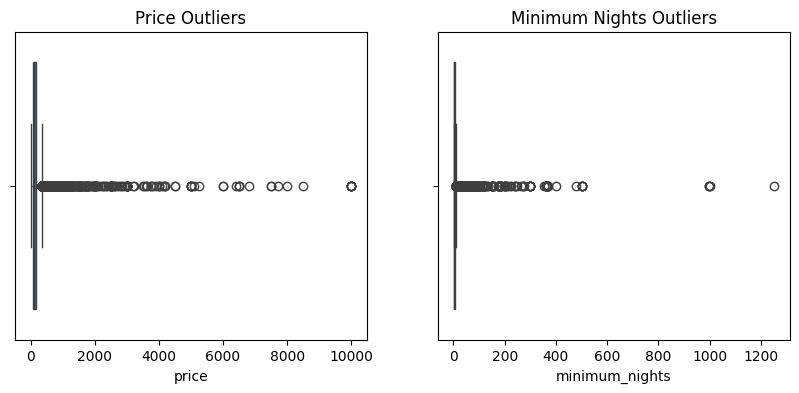

Shape after outlier removal: (46417, 10)


In [4]:
# Visualize outliers
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
sns.boxplot(x=df['price'])
plt.title("Price Outliers")

plt.subplot(1,2,2)
sns.boxplot(x=df['minimum_nights'])
plt.title("Minimum Nights Outliers")

plt.show()

# Remove extreme values using 95th percentile
price_limit = df['price'].quantile(0.95)

df = df[(df['price'] <= price_limit) &
        (df['minimum_nights'] < 365)]

print("Shape after outlier removal:", df.shape)

In [5]:
# One-Hot Encoding
df = pd.get_dummies(df, columns=['neighbourhood_group',
                                  'room_type'], drop_first=True)

# Separate features and target
X = df.drop('price', axis=1)
y = df['price']

print("Features:", X.shape)
print("Target:", y.shape)

Features: (46417, 13)
Target: (46417,)


In [6]:
# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train Linear Regression
model = LinearRegression()
model.fit(X_train, y_train)

# Predictions
y_pred = model.predict(X_test)

print("Model Training Completed!")

Model Training Completed!


In [7]:
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("========== MODEL EVALUATION ==========")
print("R2 Score:", round(r2, 4))
print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))

========== MODEL EVALUATION ==========
R2 Score: 0.4716
MAE: 37.97
MSE: 2725.05
RMSE: 52.2


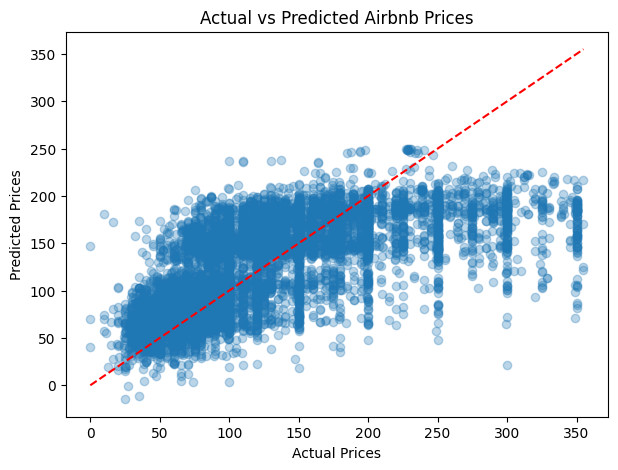

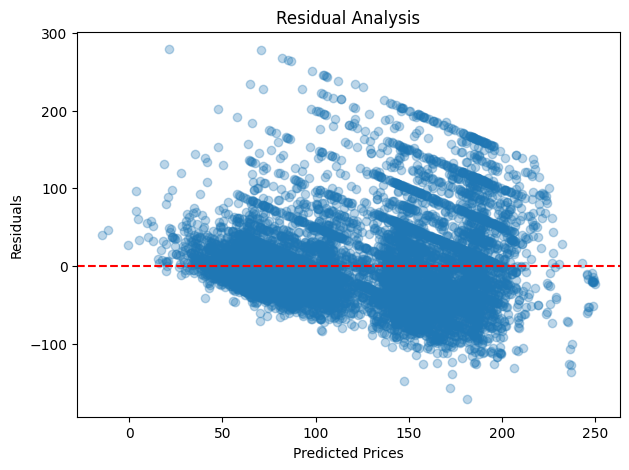

In [8]:
# Actual vs Predicted
plt.figure(figsize=(7,5))
plt.scatter(y_test, y_pred, alpha=0.3)

plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--')

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Airbnb Prices")
plt.show()

# Residual Plot
residuals = y_test - y_pred

plt.figure(figsize=(7,5))
plt.scatter(y_pred, residuals, alpha=0.3)
plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Prices")
plt.ylabel("Residuals")
plt.title("Residual Analysis")
plt.show()

In [9]:
print("R2 Score:", r2)
print("MAE:", mae)
print("MSE:", mse)
print("RMSE:", rmse)

R2 Score: 0.47155122844020947
MAE: 37.973213320172725
MSE: 2725.045755275659
RMSE: 52.20197079877022
